# How to create an NDVI Time series using openEO

This notebook presents an application case, that demonstrates how to display the NDVI (Normalized Difference Vegetation Index) timeseries for specific fields. The case study showcases the process of selecting the fields and generating average NDVI timeseries data for analysis and visualization.

## Setup

In [1]:
import json

import pandas as pd
import matplotlib.pyplot as plt
import scipy.signal
import numpy as np

import openeo

Establish an authenticated connection to Copernicus Data Space Ecosystem openEO back-end.

In [2]:
connection = openeo.connect(url="openeo.dataspace.copernicus.eu")
connection.authenticate_oidc()

Visit https://identity.dataspace.copernicus.eu/auth/realms/CDSE/device?user_code=OMKJ-FTNI 📋 to authenticate.

✅ Authorized successfully

Authenticated using device code flow.


<Connection to 'https://openeo.dataspace.copernicus.eu/openeo/1.2/' with OidcBearerAuth>

## Basic NDVI Timeseries

We want to calculate the NDVI values in a couple of fields in a time window of a couple of months.

For simplicty, we load the field geometries as an inline GeoJSON feature collection:

In [3]:
fields = json.loads(
    """{
    "type": "FeatureCollection",
    "features": [
        {"type": "Feature", "properties": {}, "geometry": {"type": "Polygon", "coordinates": [[[5.055945487931457, 51.222709834076504], [5.064972484168688, 51.221122565090525], [5.064972484168688, 51.221122565090525], [5.067474954083448, 51.218249806779134], [5.064827929485983, 51.21689628072789], [5.05917785594747, 51.217191909908095], [5.053553857094518, 51.21807492332223], [5.055945487931457, 51.222709834076504]]]}}, 
        {"type": "Feature", "properties": {}, "geometry": {"type": "Polygon", "coordinates": [[[5.063345886679116, 51.23087606640057], [5.06604742694687, 51.22886710731809], [5.070627820472246, 51.22874440121892], [5.068403609708207, 51.22657208381529], [5.064823257492447, 51.22676051738515], [5.064892324615199, 51.2283032878514], [5.063641745941974, 51.2285757299238], [5.062340811262595, 51.227722351687945], [5.06076005158084, 51.228042312276536], [5.063345886679116, 51.23087606640057]]]}},
        {"type": "Feature", "properties": {}, "geometry": {"type": "Polygon", "coordinates": [[[5.07163184674986, 51.23481147556147], [5.076706025697324, 51.23317590781036], [5.077828303041866, 51.233226237184724], [5.078024733866917, 51.23263978271262], [5.080771081607657, 51.23259097170763], [5.083734842574312, 51.23530464074437], [5.080957826735458, 51.23646091560258], [5.079752631651647, 51.23519531038643], [5.077238400183506, 51.23490534677628], [5.072856439300575, 51.23593546777778], [5.07163184674986, 51.23481147556147]]]}}, 
        {"type": "Feature", "properties": {}, "geometry": {"type": "Polygon", "coordinates": [[[5.083897244679042, 51.23510639883143], [5.081302408741335, 51.232922477780846], [5.082963802194108, 51.233146058575876], [5.084497702305552, 51.232672717580655], [5.085732850338428, 51.2340852086282], [5.083897244679042, 51.23510639883143]]]}}
    ]}
"""
)

Load the "B04" (red) and "B08" (NIR) brands from the  `SENTINEL2_L2A` collection for the desired time window:

In [4]:
s2cube = connection.load_collection(
    "SENTINEL2_L2A",
    temporal_extent=["2020-06-01", "2020-10-01"],
    bands=["B04", "B08"],
)

Note here that it is not necessary to specify a spatial extent in `load_collection`,
because we will provide the field geometries in a later step.
The openEO back-end will automatically limit the effective data loading to the necessary bounding box.

Calculate the NDVI from the red and NIR bands:

In [5]:
red = s2cube.band("B04")
nir = s2cube.band("B08")
ndvi = (nir - red) / (nir + red)

With the `DataCube.aggregate_spatial()` method , we can calculate the mean NDVI for each of the fields.

In [6]:
timeseries = ndvi.aggregate_spatial(geometries=fields, reducer="mean")

We now execute this as a batch job and download the timeseries in CSV format.

In [7]:
timeseries

In [8]:
job = timeseries.execute_batch(out_format="CSV", title="NDVI timeseries")

0:00:00 Job 'j-26100609273444eb9d921ebfa9b32594': send 'start'
0:00:02 Job 'j-26100609273444eb9d921ebfa9b32594': queued (progress 0%)
0:00:07 Job 'j-26100609273444eb9d921ebfa9b32594': queued (progress 0%)
0:00:13 Job 'j-26100609273444eb9d921ebfa9b32594': queued (progress 0%)
0:00:21 Job 'j-26100609273444eb9d921ebfa9b32594': queued (progress 0%)
0:00:31 Job 'j-26100609273444eb9d921ebfa9b32594': queued (progress 0%)
0:00:43 Job 'j-26100609273444eb9d921ebfa9b32594': queued (progress 0%)
0:00:59 Job 'j-26100609273444eb9d921ebfa9b32594': queued (progress 0%)
0:01:18 Job 'j-26100609273444eb9d921ebfa9b32594': queued (progress 0%)
0:01:42 Job 'j-26100609273444eb9d921ebfa9b32594': running (progress N/A)
0:02:12 Job 'j-26100609273444eb9d921ebfa9b32594': running (progress N/A)
0:02:49 Job 'j-26100609273444eb9d921ebfa9b32594': finished (progress 100%)


Download the timeseries CSV:

In [9]:
job.get_results().download_file("ndvi-results/timeseries-basic.csv")
pd.read_csv("ndvi-results/timeseries-basic.csv", index_col=0).head()

,feature_index,band_unnamed
date,,
2020-07-04T00:00:00.000Z,3,0.008273
2020-07-04T00:00:00.000Z,1,0.008331
2020-07-01T00:00:00.000Z,2,0.010223
2020-07-01T00:00:00.000Z,0,0.010158
2020-07-04T00:00:00.000Z,2,0.008985


The table above shows the NDVI saved under the `band_unnamed` column corresponding to their respective dates.

Let us create a quick plot helper to visualize the NDVI data:

In [10]:
def plot_timeseries(filename, figsize=(6, 3)):
    df = pd.read_csv(filename, index_col=0)
    df.index = pd.to_datetime(df.index)
    df = df.sort_index()
    fig, ax = plt.subplots(figsize=figsize, dpi=90)
    df.groupby("feature_index")["band_unnamed"].plot(marker="o", ax=ax)
    ax.set_title(filename.split("/")[-1])
    ax.set_ylabel("NDVI")
    ax.set_ylim(0, 1)
    ax.legend(title="parcel id", loc="lower left", ncol=2)

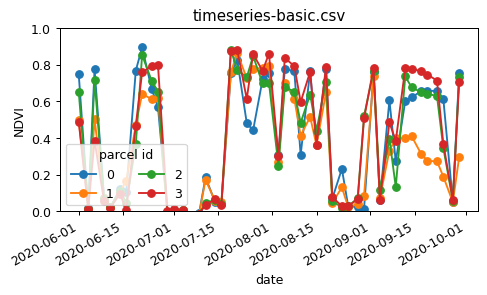

In [11]:
plot_timeseries("ndvi-results/timeseries-basic.csv")

## Cloud Masking in NDVI

The result above is a good start, but there is room for improvement to get smoother NDVI profiles.

There are quite some outliers because we didn't filter out cloudy observations or pixels.
We can use the "SCL" (scene classification) band from the "SENTINEL2_L2A" collection to focus on non-cloud pixels.
Let's load an "SENTINEL2_L2A" data cube again, with the additional "SCL" band, and calculate the NDVI like before:

In [12]:
s2cube = connection.load_collection(
    "SENTINEL2_L2A",
    temporal_extent=["2020-06-01", "2020-10-01"],
    bands=["B04", "B08", "SCL"],
)
red = s2cube.band("B04")
nir = s2cube.band("B08")
ndvi = (nir - red) / (nir + red)

Now, from the "SCL" band we will build a mask to remove everything that is not class 4 ("vegetation") or 5 ("not vegetated").
This mask data cube is 1 for pixels which we want to remove (clouds, cloud shadow, ...) and 0 for pixels we want to keep.

In [13]:
scl = s2cube.band("SCL")
mask = ~((scl == 4) | (scl == 5))

This mask is however a bit noisy (because of imperfect classification) and to be a bit conservative we also want to expand it a bit to exclude extra pixels at cloud edges. 
We can do this morphological operation by using a convolution with a gaussian kernel and applying a threshold to get a binary mask again.

In [14]:
# 2D gaussian kernel
g = scipy.signal.windows.gaussian(11, std=1.6)
kernel = np.outer(g, g)
kernel = kernel / kernel.sum()

# Morphological dilation of mask: convolution + threshold
mask = mask.apply_kernel(kernel)
mask = mask > 0.1

Now, we mask the NDVI data cube and do aggregation again:

In [15]:
ndvi_masked = ndvi.mask(mask)
timeseries_masked = ndvi_masked.aggregate_spatial(geometries=fields, reducer="mean")

In [16]:
job = timeseries_masked.execute_batch(out_format="CSV", title="Maked NDVI timeseries")

0:00:00 Job 'j-2610060930264b85a6ae0420d8ffbfc6': send 'start'
0:00:02 Job 'j-2610060930264b85a6ae0420d8ffbfc6': queued (progress 0%)
0:00:07 Job 'j-2610060930264b85a6ae0420d8ffbfc6': queued (progress 0%)
0:00:13 Job 'j-2610060930264b85a6ae0420d8ffbfc6': queued (progress 0%)
0:00:21 Job 'j-2610060930264b85a6ae0420d8ffbfc6': queued (progress 0%)
0:00:31 Job 'j-2610060930264b85a6ae0420d8ffbfc6': queued (progress 0%)
0:00:44 Job 'j-2610060930264b85a6ae0420d8ffbfc6': queued (progress 0%)
0:00:59 Job 'j-2610060930264b85a6ae0420d8ffbfc6': running (progress N/A)
0:01:19 Job 'j-2610060930264b85a6ae0420d8ffbfc6': running (progress N/A)
0:01:42 Job 'j-2610060930264b85a6ae0420d8ffbfc6': running (progress N/A)
0:02:16 Job 'j-2610060930264b85a6ae0420d8ffbfc6': running (progress N/A)
0:02:53 Job 'j-2610060930264b85a6ae0420d8ffbfc6': running (progress N/A)
0:03:40 Job 'j-2610060930264b85a6ae0420d8ffbfc6': finished (progress 100%)


In [17]:
job.get_results().download_file("ndvi-results/timeseries-masked.csv")

PosixPath('ndvi-results/timeseries-masked.csv')

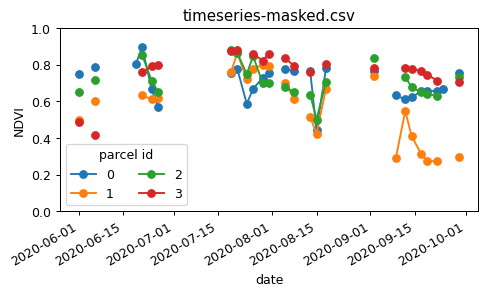

In [18]:
plot_timeseries("ndvi-results/timeseries-masked.csv")